import librararies

In [9]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


upload the dataset

In [13]:
from google.colab import files

uploaded = files.upload()

Saving Tweets.csv to Tweets (2).csv


load the dataset

In [14]:
import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


explore sentiment classes

In [15]:
print("Column Names:")
print(df.columns.tolist())

print("\nSentiment Distribution:")
print(df['airline_sentiment'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']

Sentiment Distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Missing Values:
tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5462
negativereason_confidence        4118
airline                             0
airline_sentiment_gold          14600
name                                0
negativereason_gold             14608
retweet_count                       0
text                                0
tweet_coord                     13621
tweet_created                       0
tweet_location                   4733
user_timezone                    4820
dtype:

prepare the data

In [16]:
# Select tweet text and sentiment

df = df.dropna(subset=['text', 'airline_sentiment'])

df['text'] = df['text'].astype(str).str.strip()

df = df[df['text'] != '']

X = df['text']
y = df['airline_sentiment']

print("Preprocessing completed!")

print("Input samples:", len(X))
print("\nSentiment classes:")
print(y.value_counts())

Preprocessing completed!
Input samples: 14640

Sentiment classes:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


split the dataset

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 11712
Testing samples: 2928


TF-IDF

In [18]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    sublinear_tf=True,
    strip_accents='unicode',
    min_df=1,
    max_features=50000
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training matrix: (11712, 50000)
Testing matrix: (2928, 50000)


build logostic regression model

In [19]:
lr_model = LogisticRegression(
    C=2,
    max_iter=2000,
    solver='lbfgs'
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


make predictions

In [20]:
y_pred = lr_model.predict(X_test_tfidf)

print("Predictions completed!")

print("\nActual Sentiments:")
print(y_test.head(10).tolist())

print("\nPredicted Sentiments:")
print(y_pred[:10])

Predictions completed!

Actual Sentiments:
['neutral', 'positive', 'negative', 'negative', 'negative', 'negative', 'neutral', 'negative', 'negative', 'negative']

Predicted Sentiments:
['negative' 'positive' 'negative' 'negative' 'negative' 'negative'
 'negative' 'negative' 'negative' 'neutral']


performance metrics

In [21]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("\n========== LOGISTIC REGRESSION PERFORMANCE ==========")

print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

print("=====================================================")


========== LOGISTIC REGRESSION PERFORMANCE ==========
Accuracy  : 80.94 %
Precision : 0.804
Recall    : 0.8094
F1 Score  : 0.7988


confusion matrix

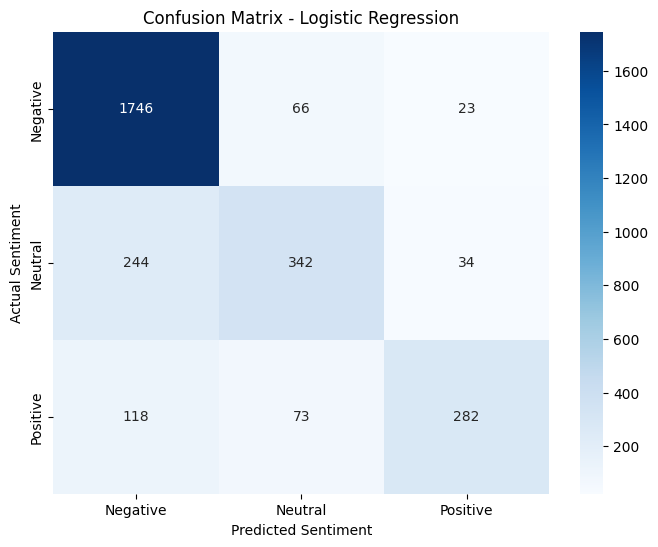

In [22]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['negative', 'neutral', 'positive']
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("Confusion Matrix - Logistic Regression")

plt.show()

testing with new teets

In [23]:
new_tweets = [
    "I am very happy with the service!",
    "The flight was delayed and I am disappointed.",
    "My flight is scheduled for tomorrow.",
    "Excellent customer service!",
    "This is the worst experience ever."
]

new_tweets_tfidf = tfidf.transform(new_tweets)

predictions = lr_model.predict(new_tweets_tfidf)

for tweet, sentiment in zip(new_tweets, predictions):

    print("Tweet:", tweet)
    print("Predicted Sentiment:", sentiment)
    print("--------------------------------")

Tweet: I am very happy with the service!
Predicted Sentiment: positive
--------------------------------
Tweet: The flight was delayed and I am disappointed.
Predicted Sentiment: negative
--------------------------------
Tweet: My flight is scheduled for tomorrow.
Predicted Sentiment: negative
--------------------------------
Tweet: Excellent customer service!
Predicted Sentiment: positive
--------------------------------
Tweet: This is the worst experience ever.
Predicted Sentiment: negative
--------------------------------
